# 01 — Data Exploration and Audit

Load the FPL dataset and audit it before modelling.

## Setup

In [1]:
import sys
sys.path.append("../src")
import pandas as pd
import matplotlib.pyplot as plt
from read_data import load_data

## Data loading

In [2]:
df = load_data()
df.shape

(841, 84)

## Check data structure and types

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 841 entries, 0 to 840
Data columns (total 84 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   id                                    841 non-null    int64  
 1   name                                  841 non-null    str    
 2   now_cost                              841 non-null    int64  
 3   position                              841 non-null    str    
 4   team                                  841 non-null    str    
 5   ict_index                             841 non-null    float64
 6   direct_freekicks_order                62 non-null     float64
 7   tackles                               841 non-null    int64  
 8   now_cost_rank_type                    841 non-null    int64  
 9   selected_rank_type                    841 non-null    int64  
 10  ep_this                               841 non-null    float64
 11  influence_rank_type           

In [4]:
with pd.option_context("display.max_rows", None):
    display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,841.0,NaN,NaN,NaN,421.0,242.920083,1.0,211.0,421.0,631.0,841.0
name,841,841,David Raya Martín,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
now_cost,841.0,NaN,NaN,NaN,48.715815,10.640392,37.0,43.0,45.0,52.0,147.0
position,841,4,MID,379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
team,841,20,Sunderland,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ict_index,841.0,NaN,NaN,NaN,45.14673,59.662806,0.0,0.0,12.7,77.9,381.4
direct_freekicks_order,62.0,NaN,NaN,NaN,2.532258,1.37564,1.0,1.0,2.0,3.0,6.0
tackles,841.0,NaN,NaN,NaN,15.019025,21.746475,0.0,0.0,2.0,25.0,119.0
now_cost_rank_type,841.0,NaN,NaN,NaN,140.199762,102.844175,1.0,53.0,115.0,220.0,379.0
selected_rank_type,841.0,NaN,NaN,NaN,140.199762,102.844175,1.0,53.0,115.0,220.0,379.0


In [5]:
df.head()

,id,name,now_cost,position,team,ict_index,direct_freekicks_order,tackles,now_cost_rank_type,selected_rank_type,...,clearances_blocks_interceptions,selected_rank,total_points,defensive_contribution,birth_date,recoveries,goals_conceded_per_90,dreamteam_count,expected_goals_conceded,threat
0,1,David Raya Martín,62,GKP,Arsenal,57.5,NaN,1,1,1,...,37,5,162,0,1995-09-15,304,0.70,2,27.56,0.0
1,2,Kepa Arrizabalaga Revuelta,40,GKP,Arsenal,2.0,NaN,0,44,37,...,3,287,2,0,1994-10-03,8,1.00,0,0.98,0.0
2,3,Karl Hein,40,GKP,Arsenal,0.0,NaN,0,54,55,...,0,385,0,0,2002-04-13,0,0.00,0,0.00,0.0
3,4,Tommy Setford,39,GKP,Arsenal,0.0,NaN,0,90,53,...,0,375,0,0,2006-03-13,0,0.00,0,0.00,0.0
4,5,Gabriel dos Santos Magalhães,73,DEF,Arsenal,125.0,NaN,38,1,1,...,239,4,209,277,1997-12-19,64,0.65,5,22.01,298.0


## Check for missing values

In [6]:
# count missing values in each column
df.isna().sum().sort_values(ascending=False)

scout_news_link                         787
penalties_order                         781
direct_freekicks_order                  779
corners_and_indirect_freekicks_order    767
known_name                              765
                                       ... 
recoveries                                0
goals_conceded_per_90                     0
dreamteam_count                           0
expected_goals_conceded                   0
threat                                    0
Length: 84, dtype: int64

In [7]:
# check if the target has missing values
df["total_points"].isna().sum()

np.int64(0)

## Check for duplicate rows

In [8]:
df.duplicated().sum()

np.int64(0)

## Check how many players with no minutes

In [9]:
# How many rows have players with 0 minutes played
(df["minutes"] == 0).sum()

np.int64(304)

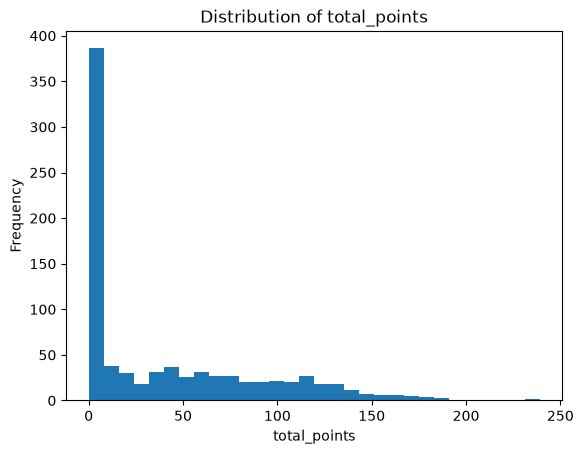

In [10]:
df["total_points"].plot.hist(bins=30)
plt.title("Distribution of total_points")
plt.xlabel("total_points")
plt.show()

## Check for outliers on the target total points

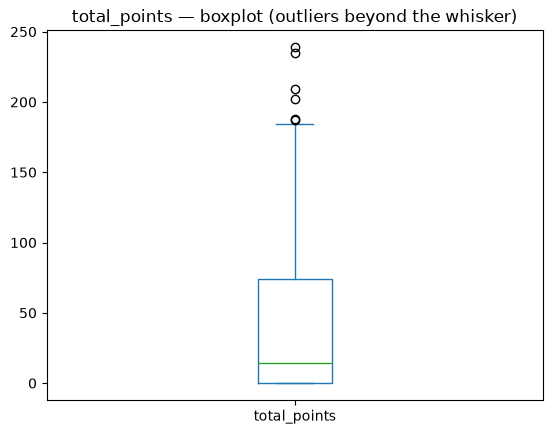

In [11]:
df["total_points"].plot.box()
plt.title("total_points — boxplot (outliers beyond the whisker)")
plt.show()

**Outliers:** The boxplot shows some players with much higher total points than the majority. These are genuine player scores rather than data errors, so they will be kept for modelling.

## Check the target value total points distribution

In [12]:
df["total_points"].describe()

count    841.000000
mean      40.882283
std       50.303358
min        0.000000
25%        0.000000
50%       14.000000
75%       74.000000
max      239.000000
Name: total_points, dtype: float64

## Summary

The dataset contains 841 players and 84 columns. There are no missing values in the features being used or in the target total_points column. There are also no duplicate rows.

304 players have played zero minutes, so these will be removed before modelling.

The distribution of total_points is right-skewed, with a small number of players scoring much higher than the majority. These outliers are genuine player scores rather than errors, so they will be kept for modelling.